اینجا میخوایم یکم آمار بازی در بیاریم و چیزای مختلف و بررسی کنیم ببینیم روی این امبدیگ چه خبره؟

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# مسیر اصلی پروژه
PROJECT_ROOT = Path.cwd().parent

# مسیر داده‌ها
DATA_DIR = PROJECT_ROOT / "data"

OBSERVATIONS_PATH = DATA_DIR / "processed" / "observations.parquet"
SPECIES_PATH = DATA_DIR / "processed" / "species.parquet"
IMAGES_PATH = DATA_DIR / "processed" / "images.parquet"
SRC_DIR = PROJECT_ROOT / "src"

EMBEDDINGS_PATH = DATA_DIR / "embeddings" / "images_dinov2.parquet"

# مسیر خروجی
OUTPUT_DIR = DATA_DIR / "features"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_PATH = OUTPUT_DIR / "wildlife_features.parquet"

# پارامترها
K = 15
GRID_DEGREES = 1.0

print("Project:", PROJECT_ROOT)
print("Output:", OUTPUT_PATH)

Project: d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2
Output: d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2\data\features\wildlife_features.parquet


In [6]:
from feature_engineering import (
    build_feature_table,
    calculate_visual_neighborhood_features,
    calculate_species_visual_spread,
    calculate_species_geographic_diversity,
    calculate_species_temporal_diversity
)

print("Feature engineering module loaded successfully.")

Feature engineering module loaded successfully.


In [7]:
features_df = build_feature_table(
    images_path=IMAGES_PATH,
    observations_path=OBSERVATIONS_PATH,
    species_path=SPECIES_PATH,
    embeddings_path=EMBEDDINGS_PATH,

    output_path=OUTPUT_PATH,

    # اگر نام ستون embedding به‌صورت خودکار تشخیص داده نشد،
    # نام دقیق آن را اینجا وارد کن.
    embedding_col=None,

    # تعداد همسایه‌های بصری
    k=K,

    # اندازه سلول مکانی بر حسب درجه
    grid_degrees=GRID_DEGREES,

    # استفاده از تمام هسته‌های CPU
    n_jobs=-1,

    # embedding اصلی در خروجی تکرار نشود
    include_embedding=False
)

print("Feature engineering completed!")
print("Output shape:", features_df.shape)
print("Output path:", OUTPUT_PATH)
print("Embedding dimensions:", features_df.attrs["embedding_dimensions"])
print("Images without embedding:", features_df.attrs["images_without_embedding"])

Feature engineering completed!
Output shape: (28132, 40)
Output path: d:\Study\SUT-CS\Books\تحلیل داده\پروژه\phase-2\data\features\wildlife_features.parquet
Embedding dimensions: 384
Images without embedding: 0


In [8]:
feature_columns = [
    "local_density",
    "visual_isolation",
    "species_visual_distance_to_centroid",
    "species_visual_spread",
    "species_visual_spread_std",
    "species_image_count",
    "geographic_observation_count",
    "geographic_unique_grid_cells",
    "geographic_diversity_entropy",
    "geographic_effective_grid_cells",
    "geographic_radius_km",
    "temporal_observation_count",
    "temporal_unique_dates",
    "temporal_unique_months",
    "temporal_month_entropy",
    "temporal_effective_months",
    "temporal_span_days"
]

available_features = [
    col for col in feature_columns
    if col in features_df.columns
]

display(features_df[available_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
local_density,28132.0,0.637841,0.087864,0.219258,0.581182,0.642697,0.699380,0.896084
visual_isolation,28132.0,0.289874,0.087994,0.025370,0.227677,0.284820,0.347061,0.690183
species_visual_distance_to_centroid,28132.0,0.371149,0.167158,0.000000,0.251950,0.337771,0.458528,1.021151
species_visual_spread,28132.0,0.371149,0.089761,0.000000,0.313264,0.371815,0.430742,0.543496
species_visual_spread_std,28132.0,0.137484,0.037671,0.000000,0.120728,0.138180,0.161029,0.299894
species_image_count,28132.0,167.710863,205.830656,1.000000,33.000000,84.000000,209.000000,900.000000
geographic_observation_count,28132.0,167.710863,205.830656,1.000000,33.000000,84.000000,209.000000,900.000000
geographic_unique_grid_cells,28132.0,21.769231,17.830066,1.000000,10.000000,18.000000,29.000000,124.000000
geographic_diversity_entropy,28132.0,1.906580,0.761690,-0.000000,1.467979,1.977006,2.340650,4.761634
geographic_effective_grid_cells,28132.0,9.635646,14.114434,1.000000,4.340453,7.221092,10.387982,116.936832


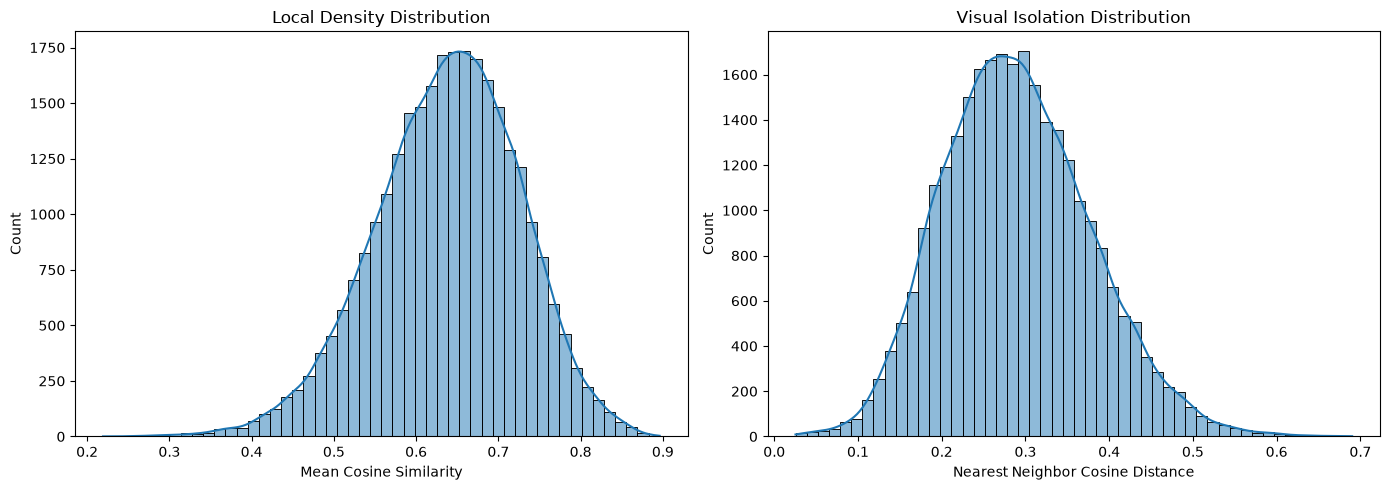

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    features_df["local_density"].dropna(),
    bins=50,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Local Density Distribution")
axes[0].set_xlabel("Mean Cosine Similarity")

sns.histplot(
    features_df["visual_isolation"].dropna(),
    bins=50,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Visual Isolation Distribution")
axes[1].set_xlabel("Nearest Neighbor Cosine Distance")

plt.tight_layout()
plt.show()

In [10]:
species_summary = (
    features_df.groupby(
        ["species_id", "common_name"],
        dropna=False
    )
    .agg(
        image_count=("image_id", "count"),
        visual_spread=("species_visual_spread", "first"),
        visual_spread_std=("species_visual_spread_std", "first")
    )
    .reset_index()
)

species_summary = species_summary.sort_values(
    "visual_spread",
    ascending=False
)

display(species_summary.head(20))

,species_id,common_name,image_count,visual_spread,visual_spread_std
707,715,Eurasian Brown Bear,28,0.543496,0.092180
714,722,Domestic Dog,597,0.539275,0.116224
49,50,House Sparrow,607,0.527528,0.134332
713,721,Red Fox,100,0.512762,0.163085
278,279,Western Barn Owl,29,0.511541,0.178657
365,366,True Sparrows,27,0.505982,0.135294
795,803,Jungle Cat,8,0.501221,0.045253
712,720,Domestic Cat,900,0.501201,0.124692
723,731,Wild Boar,67,0.500935,0.217325
708,716,Turkmenian Red Fox,97,0.500930,0.180748


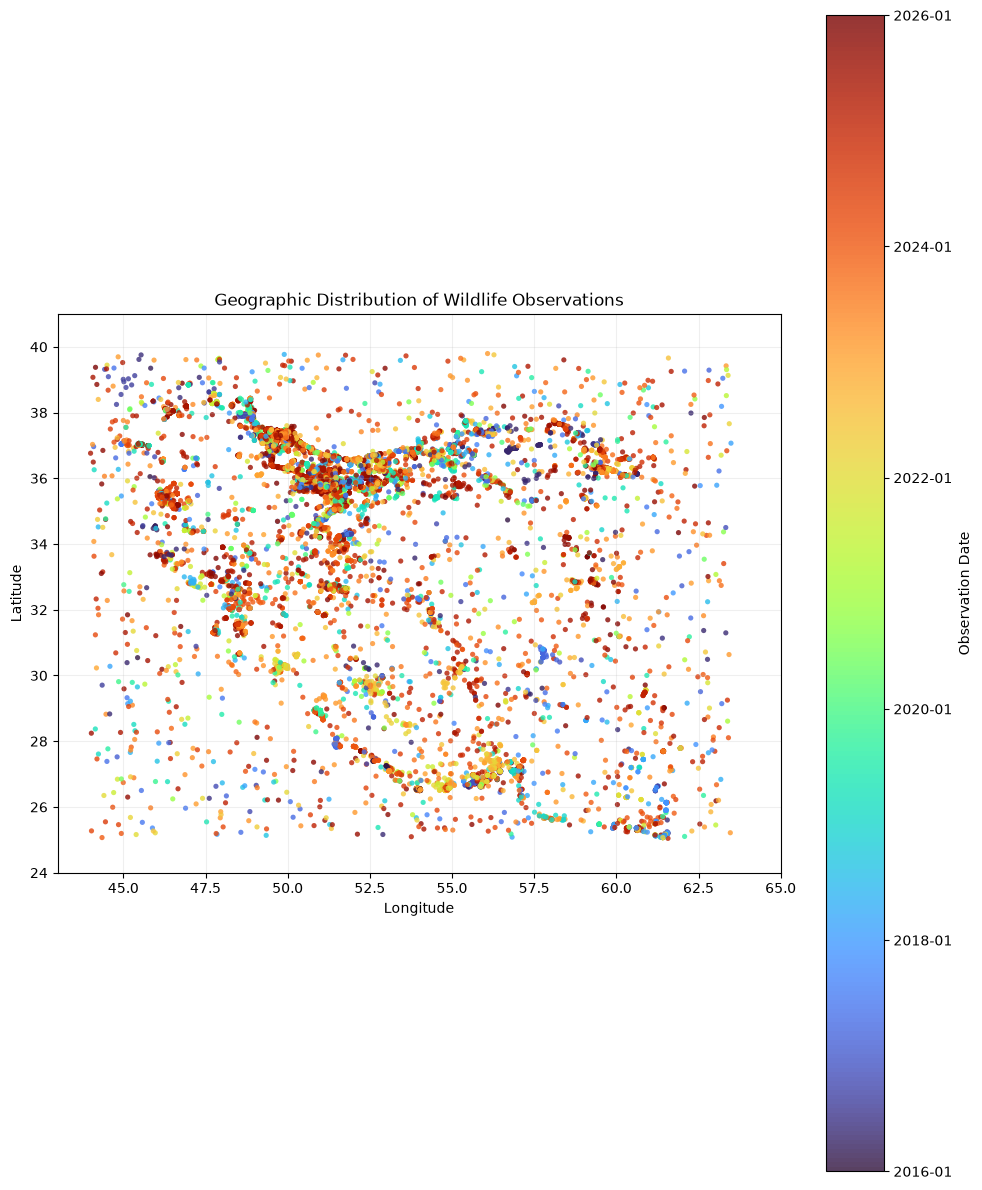

In [11]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

plot_df = features_df.drop_duplicates(subset="uuid").copy()

plot_df["observed_on"] = pd.to_datetime(
    plot_df["observed_on"], errors="coerce"
)

plot_df = plot_df.dropna(
    subset=["latitude", "longitude", "observed_on"]
)

# حذف مختصات نامعتبر
plot_df = plot_df[
    plot_df["latitude"].between(24, 41) &
    plot_df["longitude"].between(43, 65)
]

# تبدیل تاریخ به عدد
timestamps = plot_df["observed_on"].map(
    lambda x: x.timestamp()
)

norm = mpl.colors.Normalize(
    vmin=timestamps.min(),
    vmax=timestamps.max()
)

fig, ax = plt.subplots(figsize=(10, 12))

scatter = ax.scatter(
    plot_df["longitude"],
    plot_df["latitude"],
    c=timestamps,
    cmap="turbo",
    norm=norm,
    s=14,
    alpha=0.8,
    edgecolors="none"
)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Observation Date")

ticks = pd.date_range(
    plot_df["observed_on"].min(),
    plot_df["observed_on"].max(),
    periods=6
)

cbar.set_ticks([x.timestamp() for x in ticks])
cbar.set_ticklabels([x.strftime("%Y-%m") for x in ticks])

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Geographic Distribution of Wildlife Observations")

ax.set_xlim(43, 65)
ax.set_ylim(24, 41)
ax.set_aspect("equal")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

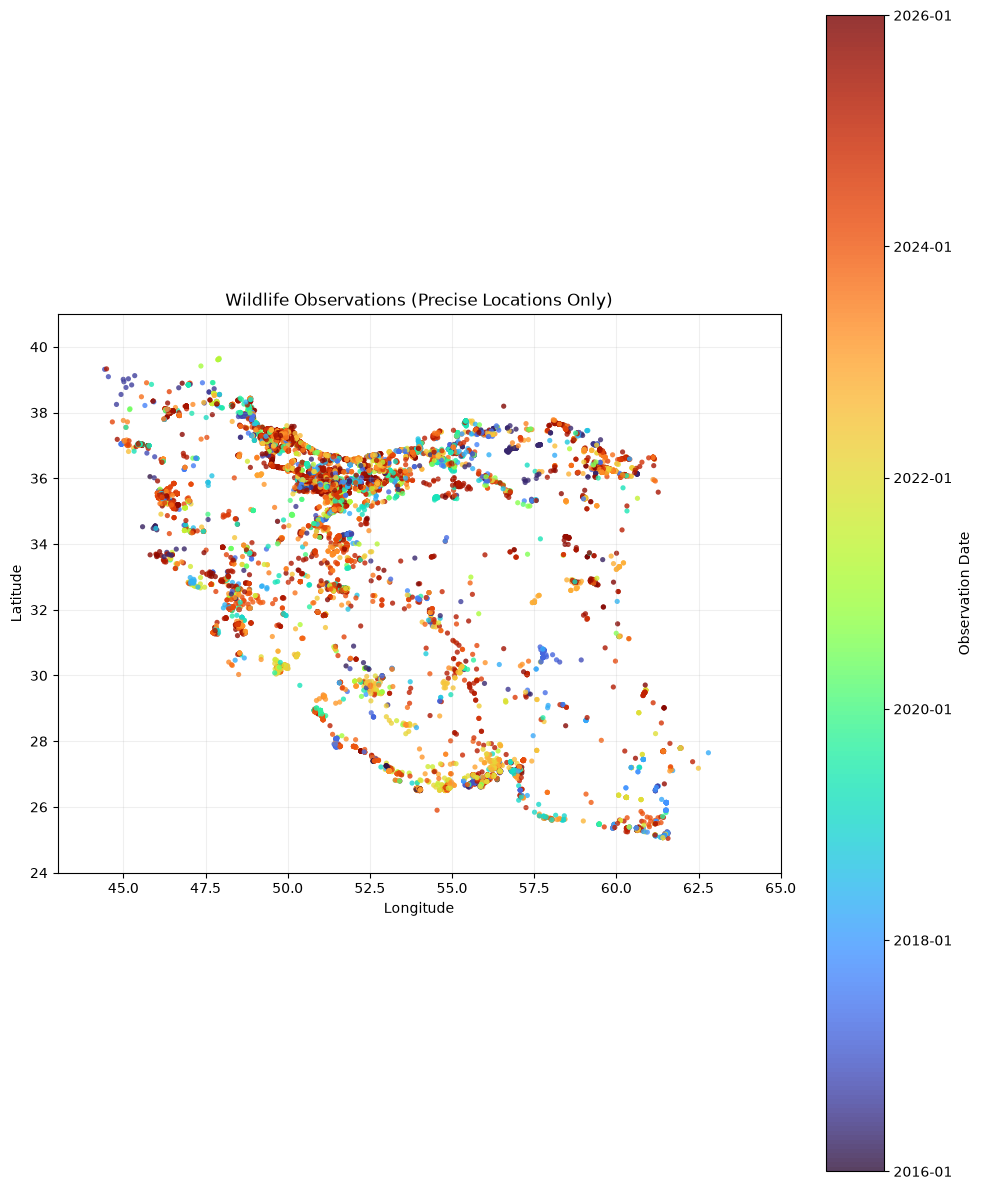

Observations plotted: 26,828


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

plot_df = features_df.drop_duplicates(subset="uuid").copy()

# حذف موقعیت‌های مخفی یا تقریبی
plot_df["taxon_geoprivacy"] = (
    plot_df["taxon_geoprivacy"]
    .astype("string")
    .str.lower()
    .str.strip()
)

plot_df = plot_df[
    ~plot_df["taxon_geoprivacy"].isin(["obscured", "private"])
].copy()

# حذف مختصات نامعتبر
plot_df["latitude"] = pd.to_numeric(plot_df["latitude"], errors="coerce")
plot_df["longitude"] = pd.to_numeric(plot_df["longitude"], errors="coerce")

plot_df["observed_on"] = pd.to_datetime(
    plot_df["observed_on"], errors="coerce"
)

plot_df = plot_df.dropna(
    subset=["latitude", "longitude", "observed_on"]
)

plot_df = plot_df[
    plot_df["latitude"].between(24, 41) &
    plot_df["longitude"].between(43, 65)
]

# رنگ بر اساس تاریخ
timestamps = plot_df["observed_on"].map(lambda x: x.timestamp())

norm = mpl.colors.Normalize(
    vmin=timestamps.min(),
    vmax=timestamps.max()
)

fig, ax = plt.subplots(figsize=(10, 12))

scatter = ax.scatter(
    plot_df["longitude"],
    plot_df["latitude"],
    c=timestamps,
    cmap="turbo",
    norm=norm,
    s=14,
    alpha=0.8,
    edgecolors="none"
)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Observation Date")

ticks = pd.date_range(
    plot_df["observed_on"].min(),
    plot_df["observed_on"].max(),
    periods=6
)

cbar.set_ticks([x.timestamp() for x in ticks])
cbar.set_ticklabels([x.strftime("%Y-%m") for x in ticks])

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Wildlife Observations (Precise Locations Only)")

ax.set_xlim(43, 65)
ax.set_ylim(24, 41)
ax.set_aspect("equal")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print(f"Observations plotted: {len(plot_df):,}")

دیدی چی شد؟ فاز اول اومدم گونه های در معرض خطر که لوکیشن هاشونو خود سایت قایم کرده بود یه نقظه شانسی دادم !همونا کلا نقشه رو عوض کرده بودن! به جای اینکه حذفشون کنم یا با میانگین پر کنم !

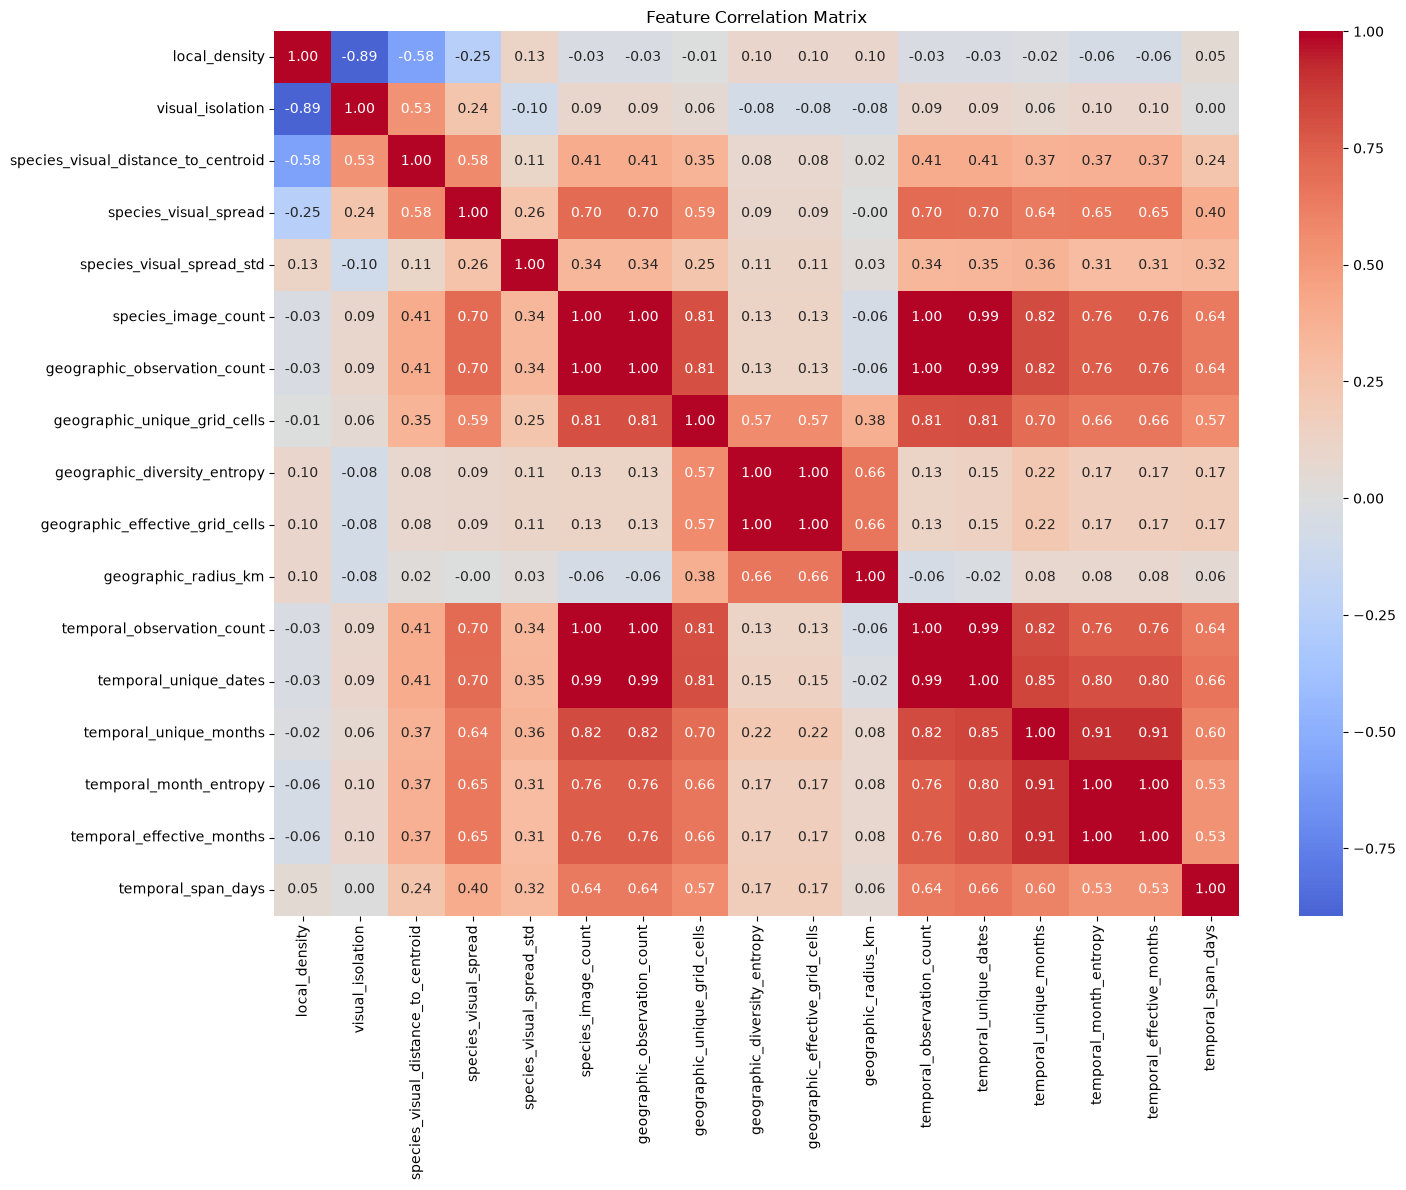

In [13]:
correlation = features_df[available_features].corr(
    method="spearman"
)

plt.figure(figsize=(15, 12))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [15]:
# ذخیره خروجی اصلی
features_df.to_parquet(
    OUTPUT_PATH,
    index=False
)

# ذخیره خلاصه گونه‌ها
species_summary.to_csv(
    OUTPUT_DIR / "species_visual_summary.csv",
    index=False
)


print("All outputs saved successfully.")

print("Files:")
for file in OUTPUT_DIR.iterdir():
    print(file.name)

All outputs saved successfully.
Files:
species_visual_summary.csv
wildlife_features.parquet
